# A/B-тест формы оплаты ЖКХ

Конверсия по уникальным пользователям: хотя бы одна успешная оплата за время эксперимента.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats
from scipy.stats import norm, chi2
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests

## Данные и проверки

In [2]:
users = pd.read_excel('dannye-dlia-keisa-po-pa-cebbefc3-5b29-4f88-b6d4-3336c88d743f.xlsx', sheet_name='Пользователи')
payments = pd.read_excel('dannye-dlia-keisa-po-pa-cebbefc3-5b29-4f88-b6d4-3336c88d743f.xlsx', sheet_name='Платежи')

print(users.shape, payments.shape)
display(users.head())
display(payments.head())

(1504, 5) (2661, 7)


,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


In [3]:
print(users.isna().sum())
print(payments.isna().sum())
print('Дубликаты:', users.duplicated().sum(), payments.duplicated().sum())
print(users['group'].value_counts(dropna=False))
print(users['age'].describe())

user_id        0
group          1
age            0
city           1
device_type    0
dtype: int64
payment_id            0
user_id               1
group                 0
step1_opened          0
step2_entered       405
step3_confirmed     942
step4_success      1139
dtype: int64
Дубликаты: 0 0
group
A      752
B      751
NaN      1
Name: count, dtype: int64
count    1504.000000
mean       32.745346
std         8.410915
min        -5.000000
25%        27.000000
50%        33.000000
75%        38.000000
max       150.000000
Name: age, dtype: float64


In [4]:
merged = payments.merge(users[['user_id', 'group']], on='user_id', how='left', suffixes=('_payment', '_user'))
mask = merged['group_payment'] != merged['group_user']
merged.loc[mask, ['payment_id', 'user_id', 'group_payment', 'group_user']]

,payment_id,user_id,group_payment,group_user
2659,99002,1010.0,B,A
2660,99003,NaN,A,NaN


In [5]:
display(payments[payments['user_id'] == 1010])
display(payments[payments['user_id'] == 1005])
display(payments[payments['user_id'].isna()])

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
14,5015,1010.0,A,2024-04-27 13:26:00,NaT,NaT,NaT
2659,99002,1010.0,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
6,5007,1005.0,A,2024-04-11 21:10:00,2024-04-11 21:11:00,NaT,NaT
2658,99001,1005.0,A,2024-04-05 10:30:00,2024-04-05 10:33:00,2024-04-05 10:38:00,2024-04-05 10:39:00


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
2660,99003,NaN,A,2024-04-12 09:15:00,NaT,NaT,NaT


In [6]:
print('Пропущен шаг 3, есть шаг 4:', ((payments['step3_confirmed'].isna()) & (payments['step4_success'].notna())).sum())
for start, end in [('step1_opened', 'step2_entered'), ('step2_entered', 'step3_confirmed'), ('step3_confirmed', 'step4_success')]:
    print(start, end, (payments[start] > payments[end]).sum())

print('Первое открытие:', payments['step1_opened'].min())
print('Последнее открытие:', payments['step1_opened'].max())

Пропущен шаг 3, есть шаг 4: 0
step1_opened step2_entered 0
step2_entered step3_confirmed 0
step3_confirmed step4_success 0
Первое открытие: 2024-04-01 00:19:00
Последнее открытие: 2024-04-30 23:17:00


In [7]:
payments_all = payments.copy()
payments = payments[(payments['user_id'].notna()) & (payments['user_id'] != 1010)].copy()
payments['success'] = payments['step4_success'].notna().astype(int)

print(payments.shape)
payments['success'].value_counts()

(2658, 8)


success
1    1521
0    1137
Name: count, dtype: int64

## Основная конверсия

In [8]:
user_success = payments.groupby('user_id')['success'].max().reset_index()
full_user_stats = user_success.merge(users, on='user_id', how='left')

stats = full_user_stats.groupby('group')['success'].agg(['count', 'sum', 'mean'])
stats

,count,sum,mean
group,,,
A,750,493,0.657333
B,750,603,0.804000


In [9]:
p_a = stats.loc['A', 'mean']
p_b = stats.loc['B', 'mean']
n_a = stats.loc['A', 'count']
n_b = stats.loc['B', 'count']
x_a = stats.loc['A', 'sum']
x_b = stats.loc['B', 'sum']

abs_conv = p_b - p_a
rel_conv = (p_b / p_a - 1) * 100
p_pool = (x_a + x_b) / (n_a + n_b)
SE = np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
Z = abs_conv / SE
p_value = norm.sf(Z)

print('Прирост:', round(abs_conv * 100, 2), 'п.п.')
print('Относительный прирост:', round(rel_conv, 2), '%')
print('Z:', Z, 'p-value:', p_value)

Прирост: 14.67 п.п.
Относительный прирост: 22.31 %
Z: 6.402393383329898 p-value: 7.64799693332123e-11


In [10]:
SE_CI = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
CI_low = (abs_conv - 1.96 * SE_CI) * 100
CI_high = (abs_conv + 1.96 * SE_CI) * 100

RR = p_b / p_a
SE_log = np.sqrt((1 - p_a) / (n_a * p_a) + (1 - p_b) / (n_b * p_b))
CI_low_rel = (np.exp(np.log(RR) - 1.96 * SE_log) - 1) * 100
CI_high_rel = (np.exp(np.log(RR) + 1.96 * SE_log) - 1) * 100

print('95% CI (п.п.):', CI_low, CI_high)
print('95% CI (%):', CI_low_rel, CI_high_rel)

95% CI (п.п.): 10.23845320946765 19.094880123865693
95% CI (%): 14.890279941051476 30.213945441205592


In [11]:
tmp = payments_all.copy()
tmp['success'] = tmp['step4_success'].notna().astype(int)
tmp = tmp.groupby('user_id')['success'].max().reset_index().merge(users[['user_id', 'group']], on='user_id', how='left')

old_result = tmp.groupby('group')['success'].mean()
print('Прирост с 1010:', (old_result['B'] - old_result['A']) * 100, 'п.п.')
print('Прирост без 1010:', abs_conv * 100, 'п.п.')

Прирост с 1010: 14.62103861517976 п.п.
Прирост без 1010: 14.666666666666671 п.п.


## Воронка

In [12]:
payments1 = payments.copy()
payments1['opened'] = payments1['step1_opened'].notna().astype(int)
payments1['entered'] = payments1['step2_entered'].notna().astype(int)
payments1['confirmed'] = payments1['step3_confirmed'].notna().astype(int)

payments2 = payments1[['user_id', 'opened', 'entered', 'confirmed', 'success']].groupby('user_id').max().reset_index()
funnel_users = payments2.merge(users[['user_id', 'group']], on='user_id', how='left')
funnel_counts = funnel_users.groupby('group')[['opened', 'entered', 'confirmed', 'success']].sum()
funnel_counts

,opened,entered,confirmed,success
group,,,,
A,750,671,548,493
B,750,707,644,603


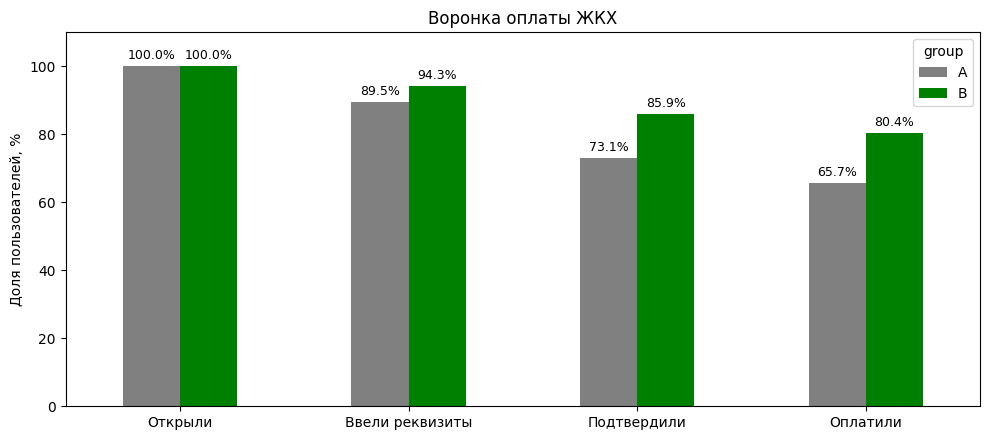

In [13]:
funnel_plt = funnel_counts.div(funnel_counts['opened'], axis=0) * 100
ax = funnel_plt.T.plot(kind='bar', figsize=(10, 4.5), color=['grey', 'green'], rot=0, ylim=(0, 110))
ax.set_title('Воронка оплаты ЖКХ')
ax.set_ylabel('Доля пользователей, %')
ax.set_xticklabels(['Открыли', 'Ввели реквизиты', 'Подтвердили', 'Оплатили'])
ax.set_xlabel('')
for i in ax.containers:
    ax.bar_label(i, fmt='%.1f%%', padding=3, fontsize=9)
plt.tight_layout()
plt.show()

## Сегменты и баланс групп

In [14]:
display(full_user_stats.groupby(['device_type', 'group'])['success'].agg(['count', 'sum', 'mean']))
display(full_user_stats.groupby(['city', 'group'])['success'].agg(['count', 'sum', 'mean']))

count  sum      mean
device_type group                      
android     A        406  262  0.645320
            B        369  295  0.799458
ios         A        344  231  0.671512
            B        381  308  0.808399

count  sum      mean
city   group                      
Москва A        287  180  0.627178
       B        306  248  0.810458
Регион A        268  179  0.667910
       B        245  187  0.763265
СПб    A        194  133  0.685567
       B        199  168  0.844221

In [15]:
age_users = full_user_stats[(full_user_stats['age'] >= 20) & (full_user_stats['age'] <= 60)].copy()
age_users['age_group'] = pd.cut(age_users['age'], [19, 29, 39, 60], labels=['20-29', '30-39', '40-60'])
age_stats = age_users.groupby(['age_group', 'group'], observed=True)['success'].agg(['count', 'sum', 'mean'])
age_stats

count  sum      mean
age_group group                      
20-29     A        268  184  0.686567
          B        267  220  0.823970
30-39     A        334  215  0.643713
          B        325  254  0.781538
40-60     A        148   94  0.635135
          B        158  129  0.816456

In [16]:
age_conv = age_stats['mean'].unstack()
D = []
W = []
for i in age_conv.index:
    a = age_stats.loc[(i, 'A')]
    b = age_stats.loc[(i, 'B')]
    D.append(b['mean'] - a['mean'])
    W.append(1 / (a['mean'] * (1-a['mean']) / a['count'] + b['mean'] * (1-b['mean']) / b['count']))

m = sum(D[i] * W[i] for i in range(3)) / sum(W)
Q = sum(W[i] * (D[i] - m)**2 for i in range(3))
print('Различие эффектов между возрастами, p:', chi2.sf(Q, 2))

Различие эффектов между возрастами, p: 0.7386762478146932


In [17]:
users_age = users[(users['age'] >= 20) & (users['age'] <= 60)].copy()
users_age['age_group'] = pd.cut(users_age['age'], [19, 29, 39, 60], labels=['20-29', '30-39', '40-60'])

device = pd.crosstab(users['device_type'], users['group'])
city = pd.crosstab(users['city'], users['group'])
age = pd.crosstab(users_age['age_group'], users_age['group'])

print('Устройства:', scipy.stats.chi2_contingency(device).pvalue)
print('Города:', scipy.stats.chi2_contingency(city).pvalue)
print('Возраст:', scipy.stats.chi2_contingency(age).pvalue)

Устройства: 0.05301515811225903
Города: 0.4658698564445901
Возраст: 0.7959222460095123


In [18]:
weights = full_user_stats['city'].value_counts(normalize=True)
city_conv = full_user_stats.groupby(['city', 'group'])['success'].mean().unstack()
print('После стандартизации по городам:')
print(city_conv.mul(weights, axis=0).sum())

weights = full_user_stats['device_type'].value_counts(normalize=True)
device_conv = full_user_stats.groupby(['device_type', 'group'])['success'].mean().unstack()
print('После стандартизации по устройствам:')
print(device_conv.mul(weights, axis=0).sum())

После стандартизации по городам:
group
A    0.656426
B    0.803159
dtype: float64
После стандартизации по устройствам:
group
A    0.657979
B    0.803779
dtype: float64


In [19]:
results = []
for col in ['device_type', 'city']:
    for segment in full_user_stats[col].dropna().unique():
        data = full_user_stats[full_user_stats[col] == segment]
        s = data.groupby('group')['success'].agg(['count', 'sum', 'mean'])
        z, p = proportions_ztest([s.loc['B', 'sum'], s.loc['A', 'sum']], [s.loc['B', 'count'], s.loc['A', 'count']])
        diff = (s.loc['B', 'mean'] - s.loc['A', 'mean']) * 100
        results.append([segment, diff, p])

segment_results = pd.DataFrame(results, columns=['segment', 'diff_pp', 'p_value'])
segment_results['p_holm'] = multipletests(segment_results['p_value'], method='holm')[1]
segment_results

,segment,diff_pp,p_value,p_holm
0,ios,13.688732,2.505795e-05,0.000075
1,android,15.413780,1.876502e-06,0.000008
2,Москва,18.327982,6.453090e-07,0.000003
3,Регион,9.535486,1.703726e-02,0.017037
4,СПб,15.865410,2.043132e-04,0.000409


In [20]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

city_users = full_user_stats.dropna(subset=['city']).copy()
model1 = smf.glm('success ~ C(group) + C(city)', data=city_users, family=sm.families.Binomial()).fit()
model2 = smf.glm('success ~ C(group) * C(city)', data=city_users, family=sm.families.Binomial()).fit()

LR = 2 * (model2.llf - model1.llf)
print('Различие эффектов между городами, p:', chi2.sf(LR, 2))

Различие эффектов между городами, p: 0.19375911127113185


## Время оплаты

In [21]:
payments['time_entered'] = (payments['step2_entered'] - payments['step1_opened']).dt.total_seconds()
payments['time_confirmed'] = (payments['step3_confirmed'] - payments['step2_entered']).dt.total_seconds()
payments['time_success'] = (payments['step4_success'] - payments['step3_confirmed']).dt.total_seconds()

for col in ['time_entered', 'time_confirmed', 'time_success']:
    print(col)
    display(payments.groupby('group')[col].agg(['count', 'mean', 'median', 'std']).round(2))

time_entered


,count,mean,median,std
group,,,,
A,1061,141.26,60.0,107.82
B,1194,145.73,60.0,115.31


time_confirmed


,count,mean,median,std
group,,,,
A,758,273.25,240.0,110.62
B,960,266.00,240.0,119.15


time_success


,count,mean,median,std
group,,,,
A,651,329.22,360.0,65.25
B,870,328.55,360.0,61.63


In [22]:
first_payments = payments.sort_values('step1_opened').drop_duplicates('user_id').copy()
first_payments['fast_entered'] = (first_payments['time_entered'] <= 180).astype(int)
first_payments.groupby('group')['fast_entered'].agg(['count', 'sum', 'mean'])

,count,sum,mean
group,,,
A,750,465,0.620000
B,750,505,0.673333


## Динамика по дням

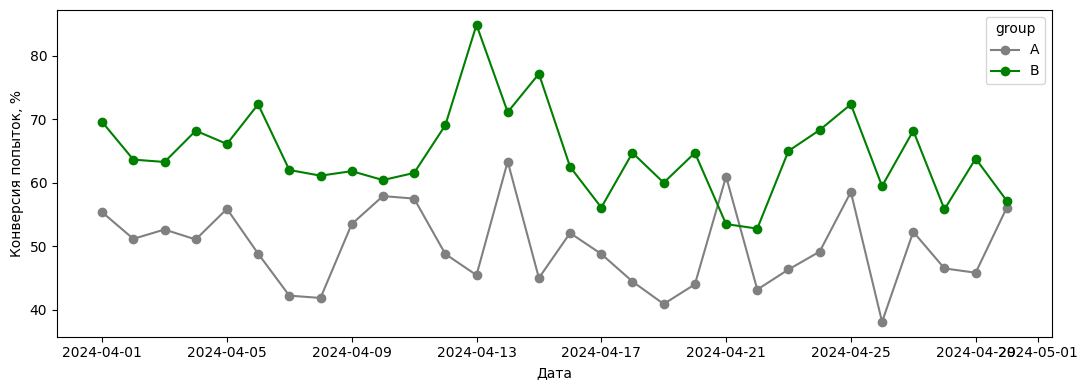

In [23]:
payments['date'] = payments['step1_opened'].dt.date
daily_stats = payments.groupby(['date', 'group'])['success'].mean().unstack()
ax = (daily_stats * 100).plot(marker='o', figsize=(11, 4), color=['grey', 'green'])
ax.set_ylabel('Конверсия попыток, %')
ax.set_xlabel('Дата')
plt.tight_layout()
plt.show()

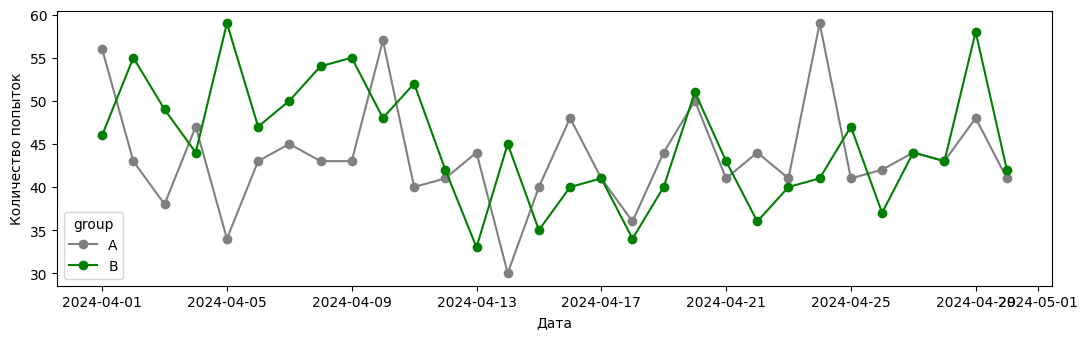

In [24]:
daily_stats_count = payments.groupby(['date', 'group'])['success'].count().unstack()
ax = daily_stats_count.plot(marker='o', figsize=(11, 3.5), color=['grey', 'green'])
ax.set_ylabel('Количество попыток')
ax.set_xlabel('Дата')
plt.tight_layout()
plt.show()

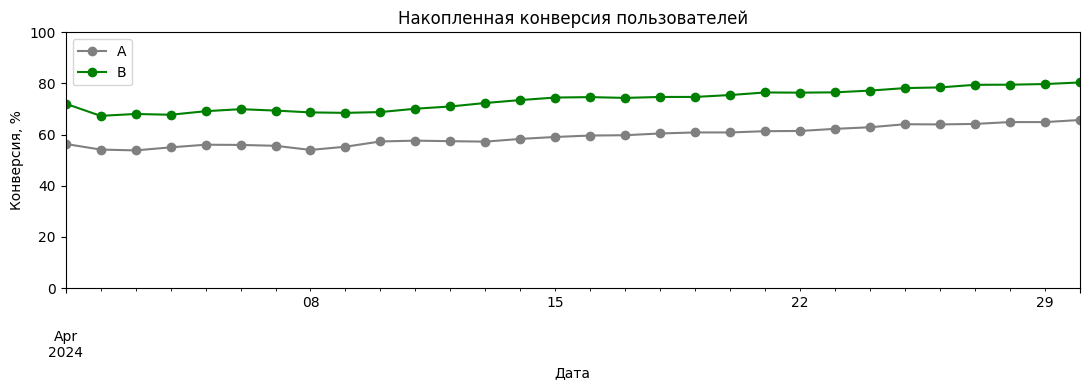

In [25]:
first_dates = payments.groupby('user_id')[['step1_opened', 'step4_success']].min().reset_index()
first_dates = first_dates.merge(users[['user_id', 'group']], on='user_id', how='left')
first_dates['first_open'] = first_dates['step1_opened'].dt.normalize()
first_dates['first_success'] = first_dates['step4_success'].dt.normalize()

dates = pd.date_range('2024-04-01', '2024-04-30')
daily_users = pd.DataFrame(index=dates)
for group in ['A', 'B']:
    data = first_dates[first_dates['group'] == group]
    opened = data['first_open'].value_counts().reindex(dates, fill_value=0).cumsum()
    success = data['first_success'].value_counts().reindex(dates, fill_value=0).cumsum()
    daily_users[group] = success / opened * 100

ax = daily_users.plot(marker='o', figsize=(11, 4), color=['grey', 'green'])
ax.set_title('Накопленная конверсия пользователей')
ax.set_ylabel('Конверсия, %')
ax.set_xlabel('Дата')
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

**Итог:** B показала более высокую конверсию. Отличия по составу групп не объясняют основной эффект. Проверки по времени и порогу 180 секунд носят разведочный характер.